# NHRF Alignment data pipeline

In [12]:
import pandas as pd
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

In [13]:
from analysis_functions import get_time_periods, get_power_data, divide_power_data_into_step_periods, compute_relative_energy_usage
from analysis_functions import plot_energy_usage, plot_multiple_datasets, plot_energy_usage_overlay_multiple_datasets

In [29]:
base_path = "../../../data/alignment-step-only"
corresponding_datasets = {
    "run1": {
        "simpipe": f"{base_path}/run1.dat", 
        "tapo": f'{base_path}/Power.xls',
        "start_time_baseline": '2026-10-30T01:30:00', 
        "end_time_baseline": '2026-10-30T10:00:00',
        "start_time_pipeline": '2026-10-29T18:01:02',
        "end_time_pipeline": '2026-10-29T19:36:38'},
    "run2": {
        "simpipe": f"{base_path}/run2.dat", 
        "tapo": f'{base_path}/Power.xls',
        "start_time_baseline": '2026-10-30T01:00:00', 
        "end_time_baseline": '2026-10-30T10:00:00',
        "start_time_pipeline": '2026-10-29T15:57:13',
        "end_time_pipeline": '2026-10-29T17:31:04'},
    "run3": {
        "simpipe": f"{base_path}/run3.dat", 
        "tapo": f'{base_path}/Power.xls',
        "start_time_baseline": '2026-10-30T01:00:00', 
        "end_time_baseline": '2026-10-30T10:00:00',
        "start_time_pipeline": '2026-10-29T13:51:24',
        "end_time_pipeline": '2026-10-29T15:27:06'},
    "run4": {
        "simpipe": f"{base_path}/run4.dat", 
        "tapo": f'{base_path}/Power.xls',
        "start_time_baseline": '2026-10-30T01:30:00', 
        "end_time_baseline": '2026-10-30T10:00:00',
        "start_time_pipeline": '2026-10-29T11:33:56',
        "end_time_pipeline": '2026-10-29T13:08:38'}
}

#nhrf-alignment-wfnqf	17:01:12	18:36:38	1h 35m 26s	0.307501	9.250
#nhrf-alignment-rjrn2	14:57:13	16:31:04	1h 33m 51s	0.302937	9.112
#nhrf-alignment-sd6bg	12:51:24	14:27:06	1h 35m 42s	0.307037	9.236
#nhrf-alignment-ffbtk	10:33:56	12:08:34	1h 34m 38s	0.304664	9.164

In [42]:
# runNr = 1, 2, 3, 4 // corresponds to 0, 1, 2, 3 in the corresponding_datasets
runNr = "run1"
path = corresponding_datasets[runNr]["simpipe"]
carbontracker_simpipe_data = pd.read_csv(path, comment='#', header=0, sep=r'\s+')
power_data = get_power_data(data_path=corresponding_datasets[runNr]["tapo"]) # get tapo power data
#power_data = get_power_data(data_path=corresponding_datasets[runNr]["tapo-filtered"]) # get tapo power data
power_data.describe()

,Date,Power(W),Energy(kWh)
count,288,288.000000,288.000000
mean,2026-10-29 22:07:30,243.621528,0.020302
min,2026-10-29 10:10:00,198.000000,0.016500
25%,2026-10-29 16:08:45,207.000000,0.017250
50%,2026-10-29 22:07:30,211.000000,0.017583
75%,2026-10-30 04:06:15,230.250000,0.019187
max,2026-10-30 10:05:00,826.000000,0.068833
std,NaN,89.996549,0.007500


In [43]:
carbontracker_simpipe_data

,step,start,stop,duration,co2,energy,status
0,nhrf-alignment-wfnqf,17:01:12,18:36:38,5716,0.307501,9.25,NaN


In [44]:
dt_format = '%Y-%m-%d %H:%M:%S'
for _, row in carbontracker_simpipe_data.iterrows():
    start_time = pd.to_datetime(row['start']).strftime(dt_format)
    stop_time = pd.to_datetime(row['stop']).strftime(dt_format)
    print(f"Step: {row['step']}, Start: {start_time}, Stop: {stop_time}")

Step: nhrf-alignment-wfnqf, Start: 2026-10-30 17:01:12, Stop: 2026-10-30 18:36:38


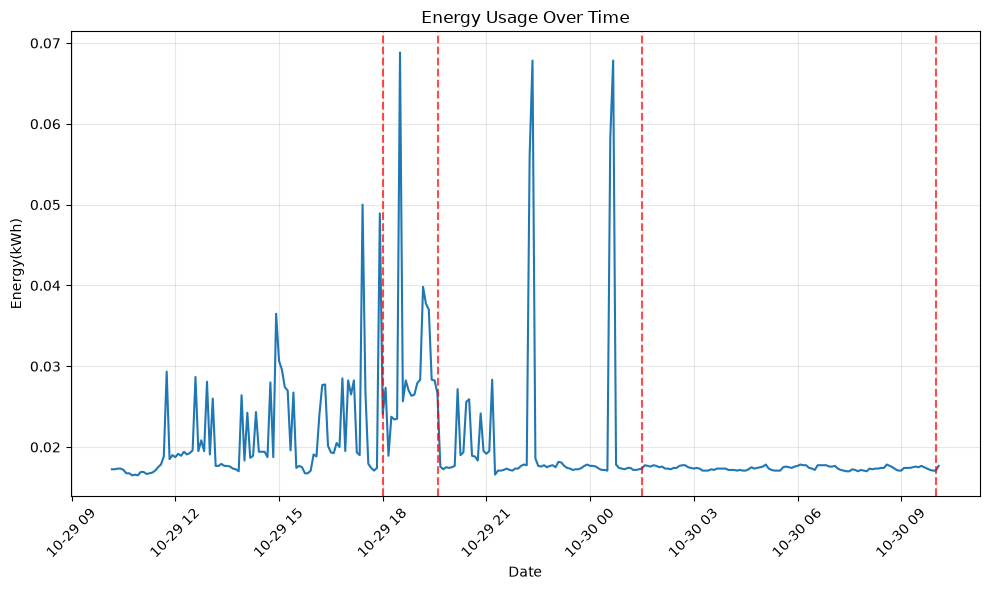

In [45]:
#raw_power_data.plot(x='Date', y='Energy(kWh)', title='Energy Usage Over Time')
#start_time = corresponding_datasets[runNr -1][2]
title = "Energy Usage Over Time"
xcol="Date"
ycol="Energy(kWh)"
start_time_baseline = corresponding_datasets[runNr]["start_time_baseline"]
end_time_baseline = corresponding_datasets[runNr]["end_time_baseline"]
start_time_pipeline = corresponding_datasets[runNr]["start_time_pipeline"]
end_time_pipeline = corresponding_datasets[runNr]["end_time_pipeline"]

timestamps = [start_time_baseline, end_time_baseline, start_time_pipeline, end_time_pipeline]

plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=None, end=None, timestamps=timestamps)
#plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=start_time_baseline, end=None, timestamps=timestamps)
#plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=start_time_baseline, end=end_time_pipeline, timestamps=timestamps)


In [46]:
time_periods = get_time_periods(carbontracker_simpipe_data, start_time_baseline, end_time_baseline)

    get_time_periods -- start and end times present. Assuming baseline period.
     appending baseline period
    get_time_periods -- extracted time periods:
      - baseline: 2026-10-30T01:30:00 to 2026-10-30T10:00:00
      - nhrf-alignment-wfnqf: 2026-10-30 17:01:12 to 2026-10-30 18:36:38


In [47]:
time_periods

[('baseline', '2026-10-30T01:30:00', '2026-10-30T10:00:00'),
 ('nhrf-alignment-wfnqf', '2026-10-30 17:01:12', '2026-10-30 18:36:38')]